# ShapeFit extensions: compression chain -> best fit -> cosmological reinterpretation

Full-machinery companion to `fs_shapefit_examples.ipynb` + `compression_examples.ipynb`, extended
with the new shape parameters of `ShapeFitSpectrum2Template` / `ShapeFitTheory`
(`dc` curvature, `deps` broadband-vs-wiggle shift, `dgam` wiggle depth; see
`shapefit_extensions.ipynb` and `desilike/theories/tests/test_shapefit_extensions.py`).

Configurations, each treated in turn (`dc` first among the additions):

| config | freed shape parameters | note |
|---|---|---|
| `baseline` | `dm` | BGV21 with the DESI MG choice `dn = 0` |
| `dc` | `dm`, `dc` | curvature added |
| `deps` | `dm`, `deps` | broadband-vs-wiggle shift added |
| `dgam` | `dm`, `dgam` | wiggle depth added |
| `dc_only` | `dc` (instead of `dm`) | curvature *replacing* the slope |

For each: sample the compression posterior, plot the best-fit curve, then feed the chain mean +
covariance to a `ShapeFitCompressionObservable` and sample the cosmological posterior over
$(h, \omega_{\rm cdm}, \log A)$ ($\omega_b$, $n_s$ fixed).  `dA` stays fixed at 1 in every
compression (with the power spectrum alone it is degenerate with `b1`); $\log A$ is nevertheless
constrained in the interpretation, because `df` measures $f\\sqrt{A_p}$ and $f$ is predicted once
$\Omega_m$ is known.  Finally all chains are plotted together with
`desilike.samples.plotting.plot_triangle`, per configuration over all its parameters.

## 1. Fake power-spectrum data (fiducial cosmology by default)

In [1]:
import os
import gc
import numpy as np
from matplotlib import pyplot as plt
from cosmoprimo.fiducial import DESI
import lsstypes

FIDUCIAL = ('DESI', {'engine': 'class'})
# data at the fiducial cosmology by default; set e.g.
# SHIFT = dict(omega_cdm=0.1206 * 1.02, n_s=0.9649 + 0.015, h=0.6736 * 0.995) for a shifted truth
SHIFT = {}
cosmo_truth = DESI(engine='camb').clone(base='input', **SHIFT) if SHIFT else DESI(engine='class')
truth = {name: float(cosmo_truth[name]) for name in ['omega_cdm', 'n_s', 'h']}

edges = np.linspace(0., 0.3, 31)
edges = np.column_stack([edges[:-1], edges[1:]])
k = np.mean(edges, axis=-1)
nmodes = 4. * np.pi / 3. * (edges[..., 1]**3 - edges[..., 0]**3)
z = 1.
pk = cosmo_truth.get_fourier().pk_interpolator(of='delta_cb')(k, z=z)
b = 2.
f = cosmo_truth.growth_rate(z)
shotnoise = np.ones_like(k) / 5e-4
volume = 1e10

ells = (0, 2, 4)
poles = np.array([(b**2 + 2. / 3. * f * b + 1. / 5. * f**2) * pk + shotnoise,
                  (4. / 3. * f * b + 4. / 7. * f**2) * pk,
                  8. / 35 * f**2 * pk], dtype='f8')

from lsstypes import Mesh2SpectrumPole, Mesh2SpectrumPoles
mean = Mesh2SpectrumPoles([Mesh2SpectrumPole(k=k, k_edges=edges, num_raw=value,
                                             num_shotnoise=(ell == 0) * shotnoise, ell=ell)
                           for ell, value in zip(ells, poles)])
cov = np.diag(np.concatenate([2. * (2. * np.pi)**3 / (2 * ell + 1) / (volume * nmodes) * poles[0]**2
                              for ell in ells]))
rng = np.random.RandomState(seed=42)
mocks = [mean.clone(value=rng.multivariate_normal(mean.value().ravel(), cov)) for i in range(1001)]
data, mocks = mocks[0], mocks[1:]
del mean, poles, cov
print('truth: omega_cdm=%.4f n_s=%.4f h=%.4f  ->  omega_m=%.4f'
      % (truth['omega_cdm'], truth['n_s'], truth['h'],
         (truth['omega_cdm'] + cosmo_truth['omega_b']) / truth['h']**2))

truth: omega_cdm=0.1200 n_s=0.9649 h=0.6736  ->  omega_m=0.3138


## 2. Compression chains and best-fit curves, one configuration per run

`dn` stays fixed to 0 everywhere (the DESI MG configuration) and `dA` to 1.

In [2]:
from desilike.theories.galaxy_clustering import ShapeFitSpectrum2Template, KaiserTracerSpectrum2Poles
from desilike.theories.galaxy_clustering.full_shape import KaiserPTSpectrum2Poles
from desilike.observables.galaxy_clustering import Spectrum2PolesObservable
from desilike.likelihoods import ObservablesGaussianLikelihood
from desilike import setup_logging, build, get_params, Sampler, Posterior
from desilike.samplers import Emcee, Zeus

setup_logging()

COMP_CONFIGS = {'baseline': dict(extra=None, fix_dm=False),
                'dc': dict(extra='dc', fix_dm=False),
                'deps': dict(extra='deps', fix_dm=False),
                'dgam': dict(extra='dgam', fix_dm=False),
                'dn' :dict(extra='dn', fix_dm=False),
               }
CONFIGS_ALL = list(COMP_CONFIGS)
# On memory-tight machines, run one configuration per kernel:
#   SFEXT_CONFIGS=dc jupyter nbconvert --to notebook --execute --inplace <this notebook>
# Each pass caches its chain and its reinterpretation under _tests/, so the reporting cells at
# the end assemble whatever is already there.  On a normal machine the default runs them all.
CONFIGS = os.environ.get('SFEXT_CONFIGS', ','.join(CONFIGS_ALL)).split(',')
CONFIGS = [config for config in CONFIGS if config in CONFIGS_ALL]

def build_compression(config):
    setup = COMP_CONFIGS[config]
    template = ShapeFitSpectrum2Template(z=z, fiducial=FIDUCIAL)
    theory = KaiserTracerSpectrum2Poles(template=template)
    data_sel = data.get(ells=[0, 2]).select(k=(0.02, 0.2))
    covariance = lsstypes.cov(mocks).at.observable.match(data_sel)
    observable = Spectrum2PolesObservable(data=data_sel, covariance=covariance, theory=theory)
    params = get_params(observable)
    params['b1'].update(value=b)
    params['dA'].update(fixed=True, value=1.)
    params['dm'].update(fixed=setup['fix_dm'], ref={'limits': [-0.001, 0.001]})
    params['df'].update(ref={'limits': [0.99, 1.01]})
    for name in ['qpar', 'qper']: params[name].update(ref={'limits': [0.998, 1.002]})
    if setup['extra'] is not None:
        params[setup['extra']].update(fixed=False)
        params[setup['extra']].update(ref={'limits': [-0.001, 0.001]})
    likelihood = ObservablesGaussianLikelihood(observables=[observable])
    return observable, likelihood

def compress(config):
    observable, likelihood = build_compression(config)
    chain_dir = os.path.join('_tests', 'chain_sfext_' + config)
    if os.path.exists(os.path.join(chain_dir, 'samples_1.h5')):
        os.remove(os.path.join(chain_dir, 'samples_1.h5'))
    sampler = Sampler(build(Posterior(likelihood)), kernel=Emcee(), rng=42, output_dir = chain_dir)
    chain = sampler.run(min_steps=300, gelman_rubin=1.02).remove_burnin(0.3)
    
    names = [name for name in ['qpar', 'qper', 'df', 'dm'] + ([COMP_CONFIGS[config]['extra']]
             if COMP_CONFIGS[config]['extra'] else []) if name in chain.names()]
    comp = dict(names=names, mean=np.array([chain.mean(name) for name in names]),
                covariance=np.asarray(chain.covariance(names)))
    os.makedirs('_tests', exist_ok=True)
    np.savez(os.path.join('_tests', 'comp_sfext_' + config + '.npz'),
             names=np.array(names), mean=comp['mean'], covariance=comp['covariance'])
    return observable, chain, comp

chains, comps = {}, {}
for config in CONFIGS:
    observable, chain, comp = compress(config)
    chains[config], comps[config] = chain, comp
    del observable, chain, comp
    gc.collect()

/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/code/cosmoprimo/main/lib/python3.12/site-packages/cosmoprimo/eisenstein_hu.py:25: UserWarning: EisensteinHuNoWiggleEngine cannot cope with massive neutrinos
  warnings.warn(


[000008.05]  10-16 00:11  EnsembleSampler              INFO     Varied parameters: ['qpar', 'qper', 'df', 'dm', 'b1', 'sn0']
[000008.05]  10-16 00:11  EnsembleSampler              INFO     Samples will be written to: _tests/chain_sfext_baseline
[000009.87]  10-16 00:11  Emcee                        INFO     total likelihood evaluations: 7176
[000009.95]  10-16 00:11  EnsembleSampler              INFO     Diagnostics:
[000009.98]  10-16 00:11  EnsembleSampler              INFO     Gelman-Rubin: 1.59
[000009.98]  10-16 00:11  EnsembleSampler              INFO     1.59 >= 1.02 (not passed)
[000009.98]  10-16 00:11  EnsembleSampler              INFO     Geweke: 1.37
[000009.98]  10-16 00:11  EnsembleSampler              INFO     Effective Sample Size: 229
[000010.35]  10-16 00:11  Emcee                        INFO     total likelihood evaluations: 14376
[000010.42]  10-16 00:11  EnsembleSampler              INFO     Diagnostics:
[000010.45]  10-16 00:11  EnsembleSampler              INFO  

/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/code/cosmoprimo/main/lib/python3.12/site-packages/cosmoprimo/eisenstein_hu.py:25: UserWarning: EisensteinHuNoWiggleEngine cannot cope with massive neutrinos
  warnings.warn(


[000017.02]  10-16 00:11  Emcee                        INFO     total likelihood evaluations: 8372
[000017.12]  10-16 00:11  EnsembleSampler              INFO     Diagnostics:
[000017.15]  10-16 00:11  EnsembleSampler              INFO     Gelman-Rubin: 1.76
[000017.15]  10-16 00:11  EnsembleSampler              INFO     1.76 >= 1.02 (not passed)
[000017.15]  10-16 00:11  EnsembleSampler              INFO     Geweke: 0.931
[000017.15]  10-16 00:11  EnsembleSampler              INFO     Effective Sample Size: 259
[000017.50]  10-16 00:11  Emcee                        INFO     total likelihood evaluations: 16772
[000017.58]  10-16 00:11  EnsembleSampler              INFO     Diagnostics:
[000017.61]  10-16 00:11  EnsembleSampler              INFO     Gelman-Rubin: 1.33
[000017.61]  10-16 00:11  EnsembleSampler              INFO     1.33 >= 1.02 (not passed)
[000017.61]  10-16 00:11  EnsembleSampler              INFO     Geweke: 1.1
[000017.61]  10-16 00:11  EnsembleSampler              I

/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/code/cosmoprimo/main/lib/python3.12/site-packages/cosmoprimo/eisenstein_hu.py:25: UserWarning: EisensteinHuNoWiggleEngine cannot cope with massive neutrinos
  warnings.warn(


[000023.42]  10-16 00:11  Emcee                        INFO     total likelihood evaluations: 8372
[000023.43]  10-16 00:11  EnsembleSampler              INFO     Diagnostics:
[000023.46]  10-16 00:11  EnsembleSampler              INFO     Gelman-Rubin: 1.17
[000023.46]  10-16 00:11  EnsembleSampler              INFO     1.17 >= 1.02 (not passed)
[000023.46]  10-16 00:11  EnsembleSampler              INFO     Geweke: 0.559
[000023.46]  10-16 00:11  EnsembleSampler              INFO     Effective Sample Size: 294
[000023.90]  10-16 00:11  Emcee                        INFO     total likelihood evaluations: 16772
[000023.91]  10-16 00:11  EnsembleSampler              INFO     Diagnostics:
[000023.94]  10-16 00:11  EnsembleSampler              INFO     Gelman-Rubin: 1.24
[000023.94]  10-16 00:11  EnsembleSampler              INFO     1.24 >= 1.02 (not passed)
[000023.94]  10-16 00:11  EnsembleSampler              INFO     Geweke: 0.782
[000023.94]  10-16 00:11  EnsembleSampler             

/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/code/cosmoprimo/main/lib/python3.12/site-packages/cosmoprimo/eisenstein_hu.py:25: UserWarning: EisensteinHuNoWiggleEngine cannot cope with massive neutrinos
  warnings.warn(


[000031.38]  10-16 00:11  Emcee                        INFO     total likelihood evaluations: 8372
[000031.38]  10-16 00:11  EnsembleSampler              INFO     Diagnostics:
[000031.41]  10-16 00:11  EnsembleSampler              INFO     Gelman-Rubin: 1.2
[000031.41]  10-16 00:11  EnsembleSampler              INFO     1.2 >= 1.02 (not passed)
[000031.41]  10-16 00:11  EnsembleSampler              INFO     Geweke: 0.863
[000031.41]  10-16 00:11  EnsembleSampler              INFO     Effective Sample Size: 313
[000031.77]  10-16 00:11  Emcee                        INFO     total likelihood evaluations: 16772
[000031.77]  10-16 00:11  EnsembleSampler              INFO     Diagnostics:
[000031.81]  10-16 00:11  EnsembleSampler              INFO     Gelman-Rubin: 1.07
[000031.81]  10-16 00:11  EnsembleSampler              INFO     1.07 >= 1.02 (not passed)
[000031.81]  10-16 00:11  EnsembleSampler              INFO     Geweke: 0.237
[000031.81]  10-16 00:11  EnsembleSampler              I

/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/code/cosmoprimo/main/lib/python3.12/site-packages/cosmoprimo/eisenstein_hu.py:25: UserWarning: EisensteinHuNoWiggleEngine cannot cope with massive neutrinos
  warnings.warn(


[000039.64]  10-16 00:11  Emcee                        INFO     total likelihood evaluations: 8372
[000039.65]  10-16 00:11  EnsembleSampler              INFO     Diagnostics:
[000039.67]  10-16 00:11  EnsembleSampler              INFO     Gelman-Rubin: 1.43
[000039.67]  10-16 00:11  EnsembleSampler              INFO     1.43 >= 1.02 (not passed)
[000039.67]  10-16 00:11  EnsembleSampler              INFO     Geweke: 0.916
[000039.67]  10-16 00:11  EnsembleSampler              INFO     Effective Sample Size: 272
[000040.06]  10-16 00:11  Emcee                        INFO     total likelihood evaluations: 16772
[000040.07]  10-16 00:11  EnsembleSampler              INFO     Diagnostics:
[000040.10]  10-16 00:11  EnsembleSampler              INFO     Gelman-Rubin: 1.24
[000040.10]  10-16 00:11  EnsembleSampler              INFO     1.24 >= 1.02 (not passed)
[000040.10]  10-16 00:11  EnsembleSampler              INFO     Geweke: 0.97
[000040.10]  10-16 00:11  EnsembleSampler              

In [3]:
def load_comp(config):
    fn = os.path.join('_tests', 'comp_sfext_' + config + '.npz')
    if not os.path.exists(fn):
        return None
    with np.load(fn, allow_pickle=True) as npz:
        return dict(names=list(npz['names']), mean=npz['mean'], covariance=npz['covariance'])

def load_chain(config):
    from desilike.samples import MCSamples
    fn = os.path.join('_tests', 'chain_sfext_' + config, 'samples_1.h5')
    return MCSamples.read(fn) if os.path.exists(fn) else None

for config in CONFIGS_ALL:
    comp = comps.get(config) or load_comp(config)
    if comp is None:
        print('== %s == (not computed yet)' % config)
        continue
    print('== %s ==' % config)
    for name, mean, cov in zip(comp['names'], comp['mean'], np.diag(comp['covariance'])):
        print('   %-5s %+.4f +/- %.4f' % (name, mean, np.sqrt(cov)))

== baseline ==
   qpar  +1.0002 +/- 0.0026
   qper  +0.9942 +/- 0.0048
   df    +0.9905 +/- 0.0097
   dm    -0.0008 +/- 0.0061
== dc ==
   qpar  +1.0001 +/- 0.0026
   qper  +0.9942 +/- 0.0049
   df    +0.9935 +/- 0.0105
   dm    -0.0204 +/- 0.0196
   dc    +0.0228 +/- 0.0218
== deps ==
   qpar  +1.0002 +/- 0.0026
   qper  +0.9942 +/- 0.0049
   df    +0.9829 +/- 0.0136
   dm    -0.0309 +/- 0.0350
   deps  +0.0320 +/- 0.0370
== dgam ==
   qpar  +1.0001 +/- 0.0026
   qper  +0.9939 +/- 0.0051
   df    +0.9902 +/- 0.0104
   dm    -0.0012 +/- 0.0059
   dgam  -0.0191 +/- 0.0323
== dn ==
   qpar  +1.0006 +/- 0.0027
   qper  +0.9946 +/- 0.0049
   df    +0.9926 +/- 0.0101
   dm    -0.0297 +/- 0.0269
   dn    +0.0186 +/- 0.0171


Best-fit curves (`observable.plot()` at the maximum-likelihood chain sample), one panel block
per configuration.

/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/code/cosmoprimo/main/lib/python3.12/site-packages/cosmoprimo/eisenstein_hu.py:25: UserWarning: EisensteinHuNoWiggleEngine cannot cope with massive neutrinos
  warnings.warn(


== best fit, baseline ==
== best fit +1sigma dm, baseline ==
== best fit -1sigma dm, baseline ==


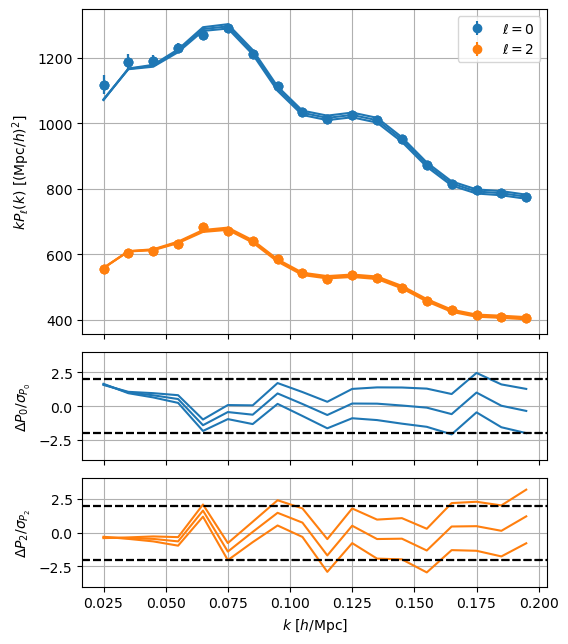

== best fit, dc ==
== best fit +1sigma dc, dc ==
== best fit -1sigma dc, dc ==


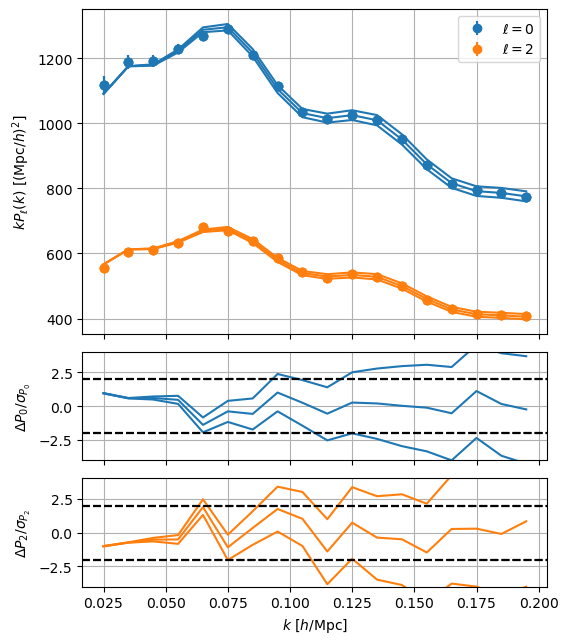

== best fit, deps ==
== best fit +1sigma deps, deps ==
== best fit -1sigma deps, deps ==


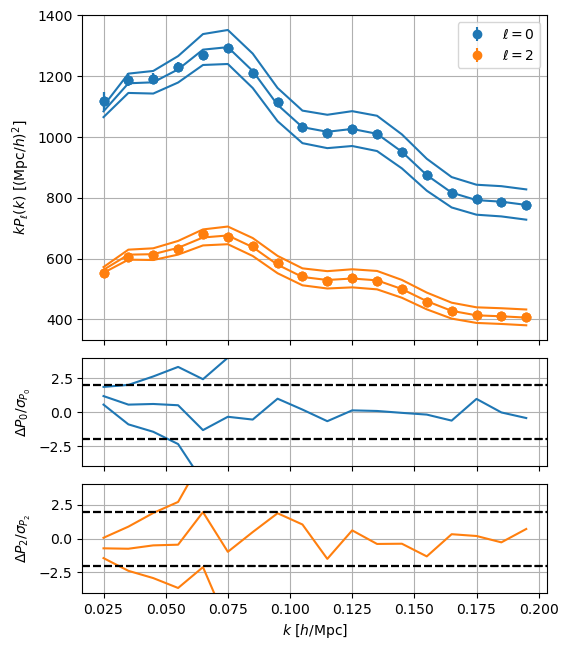

== best fit, dgam ==
== best fit +1sigma dgam, dgam ==
== best fit -1sigma dgam, dgam ==


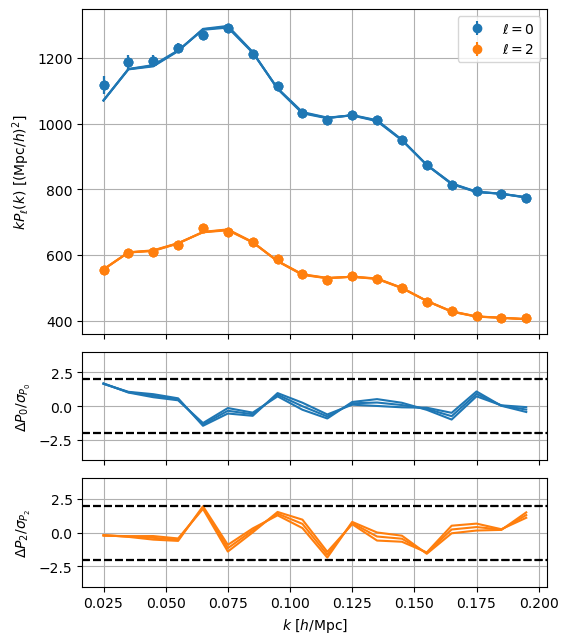

== best fit, dn ==
== best fit +1sigma dn, dn ==
== best fit -1sigma dn, dn ==


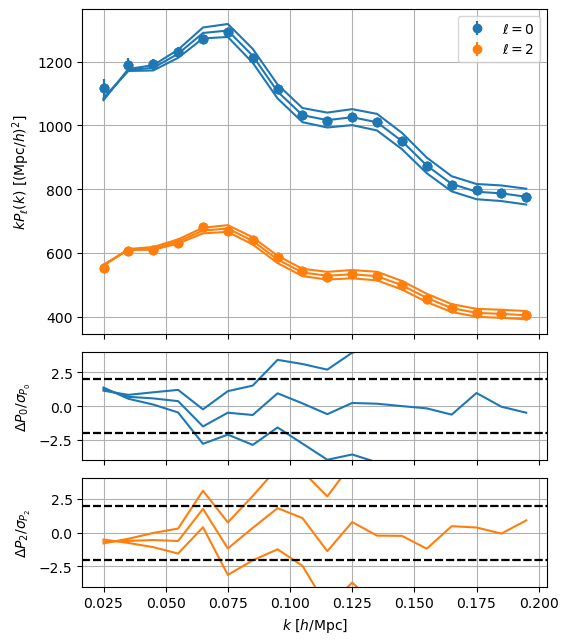

In [4]:
for config in CONFIGS_ALL:
    chain = chains.get(config) or load_chain(config)
    if chain is None:
        continue
    observable, likelihood = build_compression(config)
    pipe = build(likelihood)
    names = [param.name for param in get_params(likelihood)]
    idx = np.argmax(np.asarray(chain['loglikelihood'].value))
    best = {name: np.asarray(chain[name].value).ravel()[idx] for name in names
            if name in chain.names()}

    pipe(best)
    print('== best fit, %s ==' % config)
    fig = observable.plot(kpower=1)

    extra = COMP_CONFIGS.get(config, {}).get('extra') or 'dm'
    if extra in best:
        sigma = np.asarray(chain[extra].value).std()
        for sign, label in [(+1, '+1sigma'), (-1, '-1sigma')]:
            perturbed = dict(best)
            perturbed[extra] = best[extra] + sign * sigma
            pipe(perturbed)
            print('== best fit %s %s, %s ==' % (label, extra, config))
            fig = observable.plot(fig=fig, kpower=1)

    plt.show()
    del observable, likelihood, pipe, chain
    gc.collect()

Sanity check: for each freed extra parameter, the chain mean should match what
`ShapeFitTheory` predicts at the (here fiducial) truth.

In [5]:
from desilike.theories.galaxy_clustering import ShapeFitTheory
from desilike.theories.primordial_cosmology import CosmoprimoCosmology

theory = ShapeFitTheory(z=z, fiducial=FIDUCIAL,
                        cosmo=CosmoprimoCosmology(engine='camb', fiducial=FIDUCIAL))
pipe_theory = build(theory)
defaults = {param.name: param._value for param in get_params(theory)}
pipe_theory({**defaults, **truth})
truth_compressed = {name: float(getattr(theory, name))
                    for name in ['qpar', 'qper', 'df', 'dm', 'dc', 'deps', 'dgam', 'dn']}
for config in CONFIGS_ALL:
    comp = comps.get(config) or load_comp(config)
    if comp is None:
        print('%-9s (not computed yet)' % config)
        continue
    line = '== %-9s' % config
    for name in comp['names']:
        idx = comp['names'].index(name)
        line += '  %s: theory %+.4f  chain %+.4f +/- %.4f' % (
            name, truth_compressed[name], comp['mean'][idx], np.sqrt(comp['covariance'][idx, idx]))
    print(line)
# the Boltzmann-based theory is no longer needed: release it before the emulation steps
del theory, pipe_theory, defaults
gc.collect()
import jax as jax_module
jax_module.clear_caches()

== baseline   qpar: theory +1.0000  chain +1.0002 +/- 0.0026  qper: theory +1.0000  chain +0.9942 +/- 0.0048  df: theory +1.0001  chain +0.9905 +/- 0.0097  dm: theory +0.0007  chain -0.0008 +/- 0.0061
== dc         qpar: theory +1.0000  chain +1.0001 +/- 0.0026  qper: theory +1.0000  chain +0.9942 +/- 0.0049  df: theory +1.0001  chain +0.9935 +/- 0.0105  dm: theory +0.0007  chain -0.0204 +/- 0.0196  dc: theory -0.0004  chain +0.0228 +/- 0.0218
== deps       qpar: theory +1.0000  chain +1.0002 +/- 0.0026  qper: theory +1.0000  chain +0.9942 +/- 0.0049  df: theory +1.0001  chain +0.9829 +/- 0.0136  dm: theory +0.0007  chain -0.0309 +/- 0.0350  deps: theory +0.0002  chain +0.0320 +/- 0.0370
== dgam       qpar: theory +1.0000  chain +1.0001 +/- 0.0026  qper: theory +1.0000  chain +0.9939 +/- 0.0051  df: theory +1.0001  chain +0.9902 +/- 0.0104  dm: theory +0.0007  chain -0.0012 +/- 0.0059  dgam: theory +0.0022  chain -0.0191 +/- 0.0323
== dn         qpar: theory +1.0000  chain +1.0006 +/- 

Removed no burn in
Removed no burn in
Removed no burn in
Removed no burn in
Removed no burn in
Removed no burn in
[000077.36]  10-16 00:12  matplotlib.mathtext          INFO     Substituting symbol \perp from STIXGeneral
[000077.36]  10-16 00:12  matplotlib.mathtext          INFO     Substituting symbol \perp from STIXGeneral
[000079.96]  10-16 00:12  matplotlib.mathtext          INFO     Substituting symbol \perp from STIXGeneral
[000079.96]  10-16 00:12  matplotlib.mathtext          INFO     Substituting symbol \perp from STIXGeneral


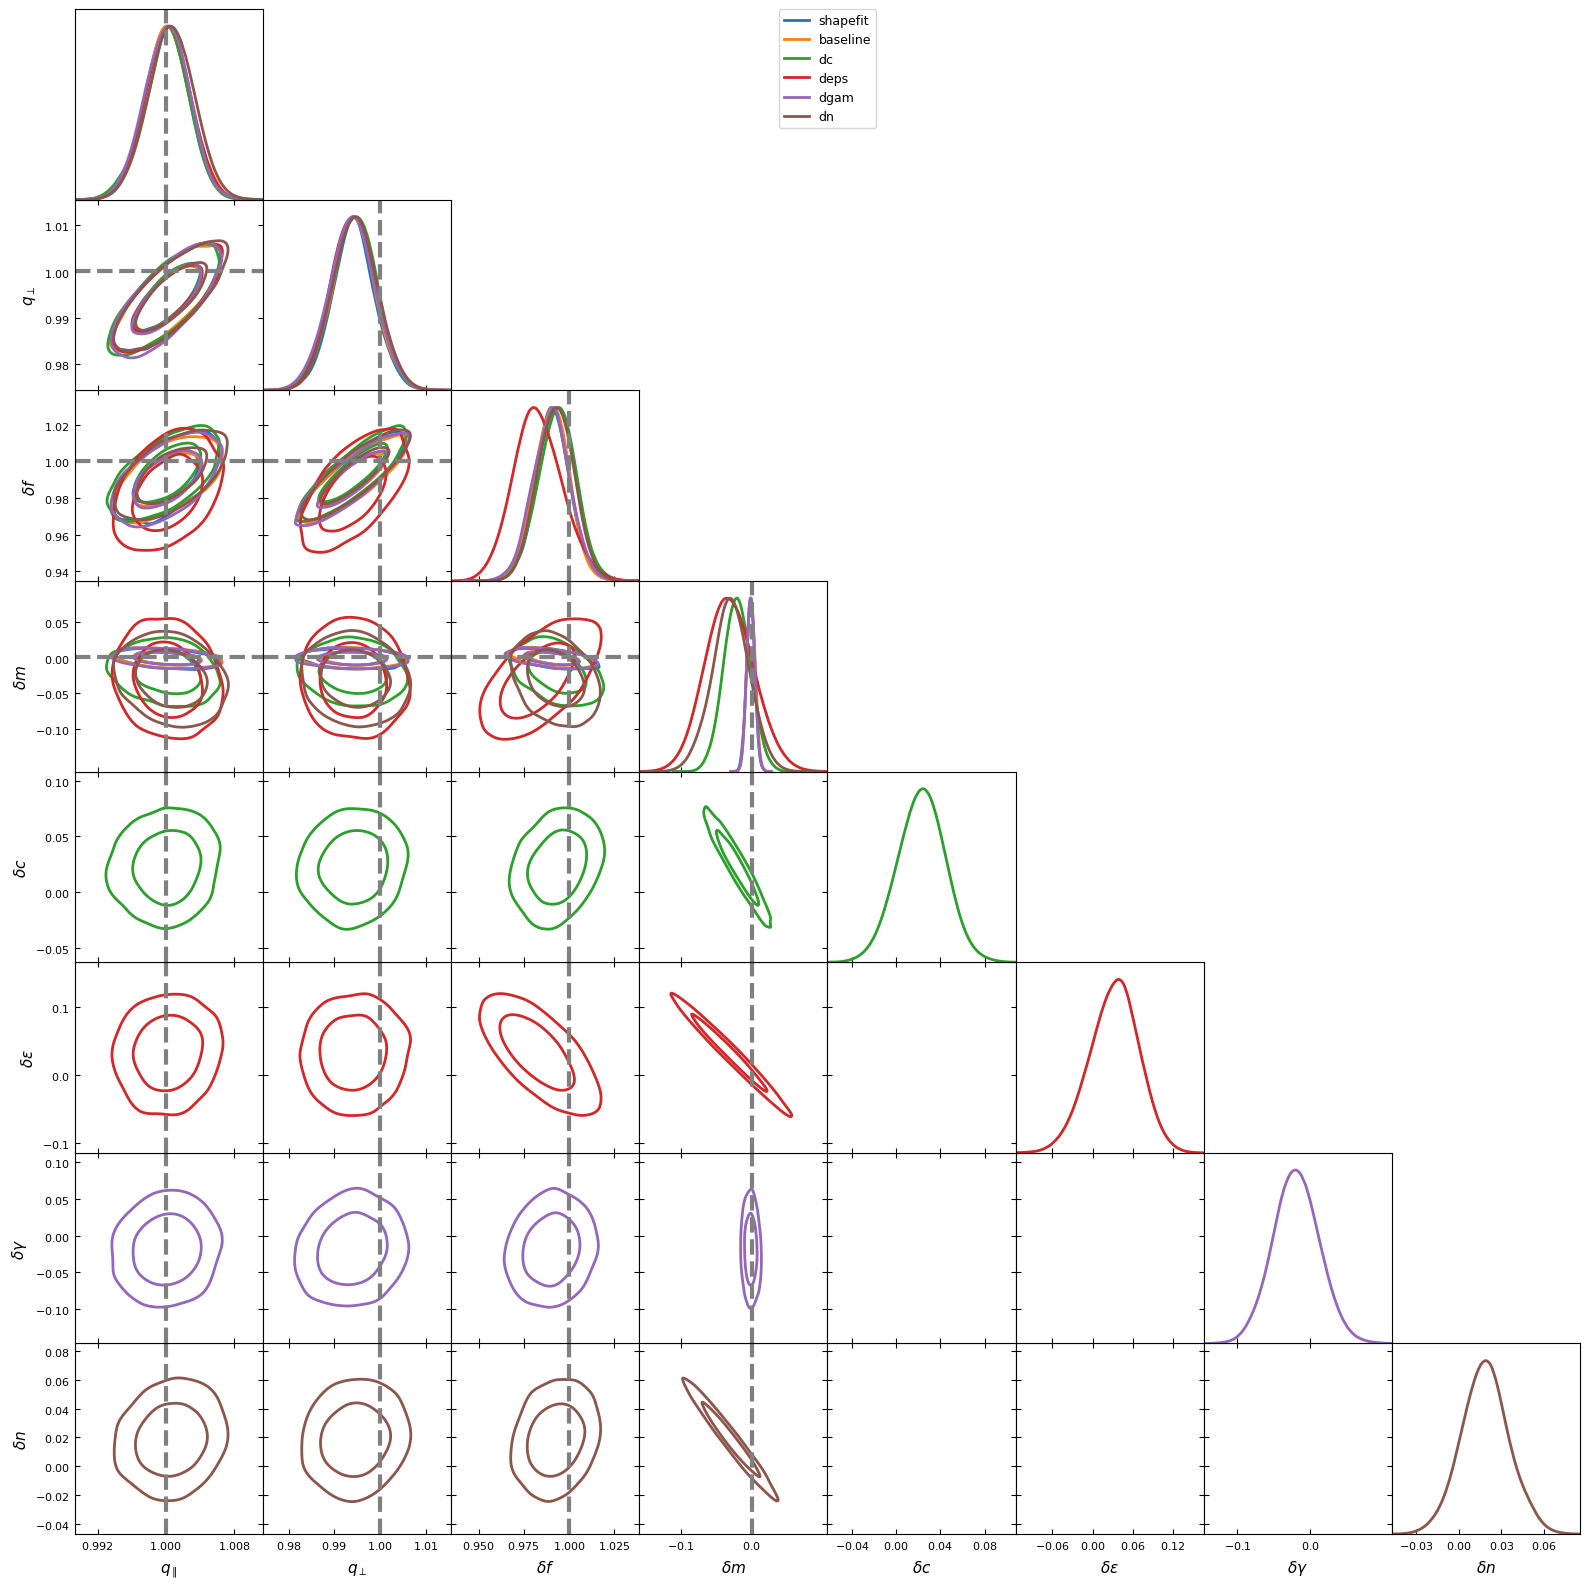

In [6]:
from desilike.samples import MCSamples, plotting

comp_chains, interp_chains = {}, {}
for config in CONFIGS_ALL:
    chain = chains.get(config) or load_chain(config)
    if chain is not None:
        comp_chains[config] = chain[::5]      # thin for plotting: keeps every figure light

overlay = [config for config in CONFIGS_ALL if config in comp_chains]
common = ['qpar', 'qper', 'df', 'dm']

chain_sf = MCSamples.read('_tests/chain_fs_shapefit/samples_1.h5').remove_burnin(0.5)

plotting.plot_triangle([chain_sf] + [comp_chains[config] for config in overlay], 
                       params=common + ['dc', 'deps', 'dgam', 'dn'], labels=['shapefit'] + overlay,
                       filled=False, markers={name: truth_compressed[name] for name in common},
                      line_args = [{'lw':3, 'color':f'C{i}'}  for i in range(10)], 
                                contour_lws = 2,
                                marker_args={"lw": 3},
                               colors = [f"C{i}" for i in range(10)],)
plt.show()
plt.close('all')

## 3. Reinterpretation with cosmology, one chain per configuration

Each compressed measurement (chain mean + covariance) becomes the data of a
`ShapeFitCompressionObservable`; the cosmological posterior over $(h, \omega_{\rm cdm}, \log A)$ is
sampled with the theory emulated on a box, as in `compression_examples.ipynb` ($\omega_b$, $n_s$
fixed).  $\log A$ is constrained here through `df` = $f\\sqrt{A_p}$: with $\Omega_m$ known from the
other compressed parameters, `df` measures the amplitude leg even though `dA` was fixed in the
compression.

In [7]:
from desilike.observables.galaxy_clustering import ShapeFitCompressionObservable
from desilike.emulators import Emulator, Space

COSMO_PARAMS = ['h', 'omega_cdm','logA', 'omega_b', 'n_s']

def reinterpret(config, comp):
    parameters = comp['names']
    print(parameters)
    observable = ShapeFitCompressionObservable(data=list(comp['mean']), covariance=comp['covariance'],
                                               parameters=parameters, z=z, fiducial=FIDUCIAL,
                                               cosmo=CosmoprimoCosmology(engine='camb', fiducial=FIDUCIAL))
    params = get_params(observable)
    params['omega_b'].update(fixed=False,
                            prior=dict(dist='norm', loc=DESI()['omega_b'], scale=0.00055),
                            ref=dict(dist='norm', loc=0.02237, scale=0.0003),
                            fd=dict(eps=0.0015), latex=r'\omega_b')
    params['n_s'].update(fixed = False,
                            value=DESI()['n_s'],
                            prior=dict(dist='norm', loc=0.9649, scale=0.042 / 10 * 2),
                            ref=dict(dist='norm', loc=DESI()['n_s'], scale=0.1),
                            fd=dict(eps=0.005), latex='n_s')
    emulator = Emulator(observable.theory, Space(bounds={'h': (0.65, 0.70),
                                                         'omega_cdm': (0.116, 0.128),
                                                         'logA': (2.97, 3.11),
                                                         'omega_b': (0.020005, 0.024995),
                                                         'n_s': (0.8, 1.1),
                                                        }), 
                        budget=1)
    emulator.train()
    observable.update(theory=emulator.to_calculator())
    likelihood = ObservablesGaussianLikelihood(observables=[observable])
    chain_dir = os.path.join('_tests', 'chain_reinterp_' + config)
    if os.path.exists(os.path.join(chain_dir, 'samples_1.h5')):
        os.remove(os.path.join(chain_dir, 'samples_1.h5'))
        
    
    sampler = Sampler(build(Posterior(likelihood)), kernel=Emcee(), rng=42)
    samples = sampler.run(min_steps=400, gelman_rubin=1.05).remove_burnin(0.4)
    os.makedirs(chain_dir, exist_ok=True)
    samples.write(os.path.join(chain_dir, 'samples_1.h5'))
    del sampler
    del likelihood, observable, emulator
    gc.collect()
    import jax
    jax.clear_caches()
    return samples

samples = {}
for config in CONFIGS:
    samples[config] = reinterpret(config, comps.get(config) or load_comp(config))

def reinterpret_samples(config):
    from desilike.samples import MCSamples
    fn = os.path.join('_tests', 'chain_reinterp_' + config, 'samples_1.h5')
    return MCSamples.read(fn).remove_burnin(0.4) if os.path.exists(fn) else None

for config in CONFIGS_ALL:
    print('reinterpretation %s: %s' % (config, 'done'
          if (config in samples or reinterpret_samples(config) is not None) else 'not computed yet'),
          flush=True)

['qpar', 'qper', 'df', 'dm']


/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/code/cosmoprimo/main/lib/python3.12/site-packages/cosmoprimo/eisenstein_hu.py:25: UserWarning: EisensteinHuNoWiggleEngine cannot cope with massive neutrinos
  warnings.warn(


[000090.13]  10-16 00:12  Emulator                     INFO     training on 11 nodes over 5 parameters; 0 handled exactly
[000090.14]  10-16 00:12  Emulator                     INFO     node box: h [0.65, 0.7], omega_cdm [0.116, 0.128], logA [2.97, 3.11], omega_b [0.020005, 0.024995], n_s [0.8, 1.1]
[000090.14]  10-16 00:12  TrainingSet                  INFO     11/11 nodes to evaluate; no checkpoint (nothing is resumable)
[000114.49]  10-16 00:12  TrainingSet                  INFO     training complete (11/11 nodes)
[000115.66]  10-16 00:13  EnsembleSampler              INFO     Varied parameters: ['h', 'omega_cdm', 'logA', 'omega_b', 'n_s']
[000117.84]  10-16 00:13  Emcee                        INFO     total likelihood evaluations: 5980
[000117.90]  10-16 00:13  EnsembleSampler              INFO     Diagnostics:
[000117.92]  10-16 00:13  EnsembleSampler              INFO     Gelman-Rubin: 1.04
[000117.92]  10-16 00:13  EnsembleSampler              INFO     1.04 < 1.05 (passed)
[0001

/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/code/cosmoprimo/main/lib/python3.12/site-packages/cosmoprimo/eisenstein_hu.py:25: UserWarning: EisensteinHuNoWiggleEngine cannot cope with massive neutrinos
  warnings.warn(


[000128.88]  10-16 00:13  Emulator                     INFO     training on 11 nodes over 5 parameters; 0 handled exactly
[000128.88]  10-16 00:13  Emulator                     INFO     node box: h [0.65, 0.7], omega_cdm [0.116, 0.128], logA [2.97, 3.11], omega_b [0.020005, 0.024995], n_s [0.8, 1.1]
[000128.88]  10-16 00:13  TrainingSet                  INFO     11/11 nodes to evaluate; no checkpoint (nothing is resumable)
[000152.91]  10-16 00:13  TrainingSet                  INFO     training complete (11/11 nodes)
[000154.09]  10-16 00:13  EnsembleSampler              INFO     Varied parameters: ['h', 'omega_cdm', 'logA', 'omega_b', 'n_s']
[000156.54]  10-16 00:13  Emcee                        INFO     total likelihood evaluations: 5980
[000156.60]  10-16 00:13  EnsembleSampler              INFO     Diagnostics:
[000156.62]  10-16 00:13  EnsembleSampler              INFO     Gelman-Rubin: 1.11
[000156.62]  10-16 00:13  EnsembleSampler              INFO     1.11 >= 1.05 (not passed)


...

[000167.56]  10-16 00:13  Emulator                     INFO     training on 11 nodes over 5 parameters; 0 handled exactly
[000167.56]  10-16 00:13  Emulator                     INFO     node box: h [0.65, 0.7], omega_cdm [0.116, 0.128], logA [2.97, 3.11], omega_b [0.020005, 0.024995], n_s [0.8, 1.1]
[000167.56]  10-16 00:13  TrainingSet                  INFO     11/11 nodes to evaluate; no checkpoint (nothing is resumable)
[000191.95]  10-16 00:14  TrainingSet                  INFO     training complete (11/11 nodes)
[000193.11]  10-16 00:14  EnsembleSampler              INFO     Varied parameters: ['h', 'omega_cdm', 'logA', 'omega_b', 'n_s']
[000195.50]  10-16 00:14  Emcee                        INFO     total likelihood evaluations: 5980
[000195.56]  10-16 00:14  EnsembleSampler              INFO     Diagnostics:
[000195.58]  10-16 00:14  EnsembleSampler              INFO     Gelman-Rubin: 1.04
[000195.58]  10-16 00:14  EnsembleSampler              INFO     1.04 < 1.05 (passed)
[0001

/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/code/cosmoprimo/main/lib/python3.12/site-packages/cosmoprimo/eisenstein_hu.py:25: UserWarning: EisensteinHuNoWiggleEngine cannot cope with massive neutrinos
  warnings.warn(


[000205.73]  10-16 00:14  Emulator                     INFO     training on 11 nodes over 5 parameters; 0 handled exactly
[000205.73]  10-16 00:14  Emulator                     INFO     node box: h [0.65, 0.7], omega_cdm [0.116, 0.128], logA [2.97, 3.11], omega_b [0.020005, 0.024995], n_s [0.8, 1.1]
[000205.74]  10-16 00:14  TrainingSet                  INFO     11/11 nodes to evaluate; no checkpoint (nothing is resumable)
[000230.07]  10-16 00:14  TrainingSet                  INFO     training complete (11/11 nodes)
[000231.21]  10-16 00:14  EnsembleSampler              INFO     Varied parameters: ['h', 'omega_cdm', 'logA', 'omega_b', 'n_s']
[000233.67]  10-16 00:14  Emcee                        INFO     total likelihood evaluations: 5980
[000233.74]  10-16 00:14  EnsembleSampler              INFO     Diagnostics:
[000233.75]  10-16 00:14  EnsembleSampler              INFO     Gelman-Rubin: 1.04
[000233.75]  10-16 00:14  EnsembleSampler              INFO     1.04 < 1.05 (passed)
[0002

/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/code/cosmoprimo/main/lib/python3.12/site-packages/cosmoprimo/eisenstein_hu.py:25: UserWarning: EisensteinHuNoWiggleEngine cannot cope with massive neutrinos
  warnings.warn(


[000243.69]  10-16 00:15  Emulator                     INFO     training on 11 nodes over 5 parameters; 0 handled exactly
[000243.69]  10-16 00:15  Emulator                     INFO     node box: h [0.65, 0.7], omega_cdm [0.116, 0.128], logA [2.97, 3.11], omega_b [0.020005, 0.024995], n_s [0.8, 1.1]
[000243.69]  10-16 00:15  TrainingSet                  INFO     11/11 nodes to evaluate; no checkpoint (nothing is resumable)
[000268.04]  10-16 00:15  TrainingSet                  INFO     training complete (11/11 nodes)
[000269.19]  10-16 00:15  EnsembleSampler              INFO     Varied parameters: ['h', 'omega_cdm', 'logA', 'omega_b', 'n_s']
[000271.64]  10-16 00:15  Emcee                        INFO     total likelihood evaluations: 5980
[000271.70]  10-16 00:15  EnsembleSampler              INFO     Diagnostics:
[000271.72]  10-16 00:15  EnsembleSampler              INFO     Gelman-Rubin: 1.12
[000271.72]  10-16 00:15  EnsembleSampler              INFO     1.12 >= 1.05 (not passed)


In [8]:

omega_b = DESI(engine='camb')['omega_b']
omega_m_truth = (truth['omega_cdm'] + omega_b) / truth['h'] ** 2
summary = {}
for config in CONFIGS_ALL:
    samp = samples.get(config) or reinterpret_samples(config)
    if samp is None:
        print('%-9s  (not computed in this session yet)' % config)
        continue
    arr = {name: np.asarray(samp[name].value).ravel() for name in COSMO_PARAMS}
    omega_m = (arr['omega_cdm'] + omega_b) / arr['h'] ** 2
    summary[config] = (omega_m.mean(), omega_m.std())
    print('%-9s  omega_m = %.4f +/- %.4f (%.1f%%)  pull vs truth = %+.1f sigma   h = %.4f +/- %.4f   logA = %.3f +/- %.3f'
          % (config, omega_m.mean(), omega_m.std(), 100 * omega_m.std() / omega_m.mean(),
             (omega_m.mean() - omega_m_truth) / omega_m.std(), arr['h'].mean(), arr['h'].std(),
             arr['logA'].mean(), arr['logA'].std()))

baseline   omega_m = 0.3077 +/- 0.0054 (1.8%)  pull vs truth = -1.1 sigma   h = 0.6780 +/- 0.0065   logA = 3.046 +/- 0.015
dc         omega_m = 0.3070 +/- 0.0056 (1.8%)  pull vs truth = -1.2 sigma   h = 0.6781 +/- 0.0066   logA = 3.047 +/- 0.015
deps       omega_m = 0.3085 +/- 0.0050 (1.6%)  pull vs truth = -1.0 sigma   h = 0.6788 +/- 0.0066   logA = 3.043 +/- 0.019
dgam       omega_m = 0.3099 +/- 0.0049 (1.6%)  pull vs truth = -0.8 sigma   h = 0.6765 +/- 0.0060   logA = 3.043 +/- 0.015
dn         omega_m = 0.3045 +/- 0.0057 (1.9%)  pull vs truth = -1.6 sigma   h = 0.6796 +/- 0.0066   logA = 3.045 +/- 0.014


In [9]:
from desilike.samples import MCSamples, plotting

comp_chains, interp_chains = {}, {}
for config in CONFIGS_ALL:
    samp = samples.get(config) or reinterpret_samples(config)
    if samp is not None:
        interp_chains[config] = samp[::5]



Removed no burn in
Removed no burn in
Removed no burn in
Removed no burn in
Removed no burn in
Removed no burn in


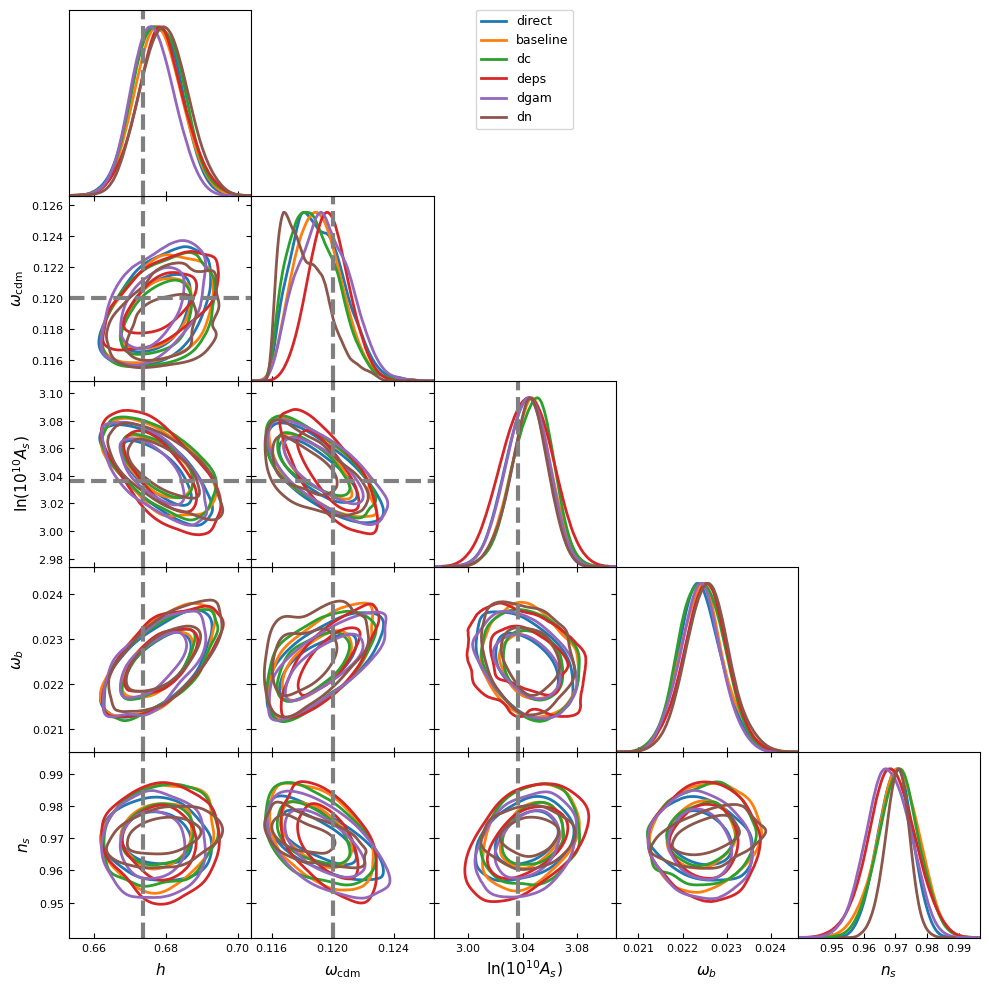

5260

In [10]:
chain_direct = MCSamples.read('_tests/chain_fs_direct/samples_1.h5').remove_burnin(0.5)[::5]
present = [config for config in CONFIGS_ALL if config in interp_chains]
plotting.plot_triangle([chain_direct] + [interp_chains[config] for config in present], params=COSMO_PARAMS,
                       labels=['direct'] + present, filled=False,
                       markers={'h': truth['omega_cdm'] and truth['h'], 'omega_cdm': truth['omega_cdm'],
                                'logA': np.log(1e10 * cosmo_truth['A_s'])},
                      line_args = [{'lw':3, 'color':f'C{i}'}  for i in range(10)], 
                                contour_lws = 2,
                                marker_args={"lw": 3},
                               colors = [f"C{i}" for i in range(10)],)
plt.show()
plt.close('all')
del comp_chains, interp_chains
gc.collect()